Closed-form solution:
 [ 1.39345523  0.92450477  0.05639062 -0.64172548  0.69208525]

Gradient Descent solution:
 [ 1.39345523  0.92450477  0.05639062 -0.64172548  0.69208525]

Difference norm: 2.336347319349354e-15


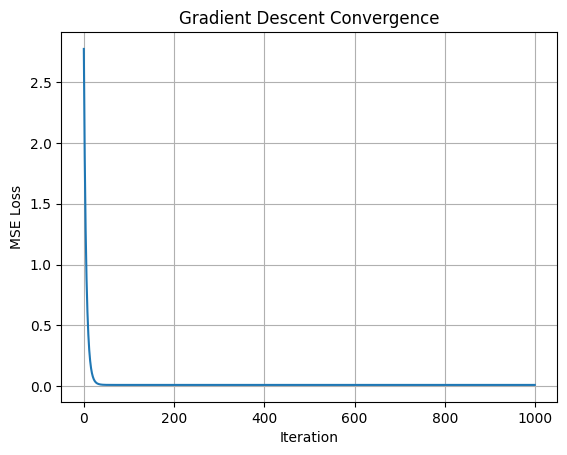

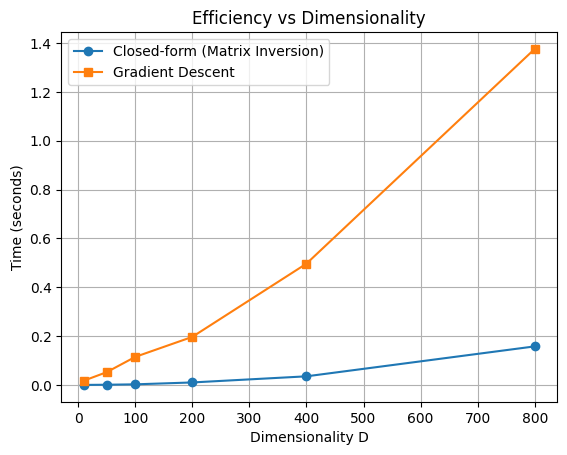

In [ ]:
# ===============================
# Linear Regression: Closed Form vs Gradient Descent
# Google Colab Ready
# ===============================

import numpy as np
import matplotlib.pyplot as plt
import time

np.random.seed(42)

# -------------------------------
# Gradient Descent Implementation
# -------------------------------
def gradient_descent(X, t, lr=0.01, epochs=1000):
    N, D = X.shape
    w = np.zeros(D)
    losses = []

    for _ in range(epochs):
        grad = (2 / N) * X.T @ (X @ w - t)
        w -= lr * grad
        loss = np.mean((X @ w - t) ** 2)
        losses.append(loss)

    return w, losses

# -------------------------------
# Single Experiment (Correctness)
# -------------------------------
N = 200      # samples
D = 5        # dimensions

X = np.random.randn(N, D)
true_w = np.random.randn(D)
t = X @ true_w + 0.1 * np.random.randn(N)

# Closed-form solution
w_closed = np.linalg.inv(X.T @ X) @ X.T @ t

# Gradient Descent solution
w_gd, losses = gradient_descent(X, t, lr=0.05, epochs=1000)

print("Closed-form solution:\n", w_closed)
print("\nGradient Descent solution:\n", w_gd)
print("\nDifference norm:", np.linalg.norm(w_closed - w_gd))

# Plot convergence
plt.figure()
plt.plot(losses)
plt.xlabel("Iteration")
plt.ylabel("MSE Loss")
plt.title("Gradient Descent Convergence")
plt.grid()
plt.show()

# -------------------------------
# Efficiency Experiment
# -------------------------------
Ds = [10, 50, 100, 200, 400, 800]
N = 1500

times_closed = []
times_gd = []

for D in Ds:
    X = np.random.randn(N, D)
    t = np.random.randn(N)

    # Closed-form timing
    start = time.time()
    w = np.linalg.inv(X.T @ X) @ X.T @ t
    times_closed.append(time.time() - start)

    # Gradient descent timing
    start = time.time()
    _ = gradient_descent(X, t, lr=0.01, epochs=300)
    times_gd.append(time.time() - start)

# Plot efficiency comparison
plt.figure()
plt.plot(Ds, times_closed, label="Closed-form (Matrix Inversion)", marker="o")
plt.plot(Ds, times_gd, label="Gradient Descent", marker="s")
plt.xlabel("Dimensionality D")
plt.ylabel("Time (seconds)")
plt.title("Efficiency vs Dimensionality")
plt.legend()
plt.grid()
plt.show()


In [ ]:
import numpy as np
import time
from ipywidgets import interact, IntSlider


In [ ]:
def closed_form(X, t):
    return np.linalg.pinv(X) @ t   # Moore–Penrose (theoretically correct)

def gradient_descent(X, t, lr=0.05, max_epochs=200, tol=1e-6):
    N, D = X.shape
    w = np.zeros(D)
    prev_loss = np.inf

    for epoch in range(max_epochs):
        grad = (2/N) * X.T @ (X @ w - t)
        w -= lr * grad
        loss = np.mean((X @ w - t)**2)
        if abs(prev_loss - loss) < tol:
            break
        prev_loss = loss

    return w, epoch + 1


In [ ]:
@interact(
    N=IntSlider(min=200, max=5000, step=200, value=1000, description="Samples (N)"),
    D=IntSlider(min=200, max=3000, step=200, value=800, description="Dimensions (D)")
)
def theory_demo(N, D):

    X = np.random.randn(N, D)
    true_w = np.random.randn(D)
    t = X @ true_w + 0.01 * np.random.randn(N)

    # Identify regime
    if N < D:
        regime = "UNDERDETERMINED (N < D)"
    elif N > D:
        regime = "OVERDETERMINED (N > D)"
    else:
        regime = "INTERPOLATING (N ≈ D)"

    # Closed-form
    t0 = time.time()
    w_cf = closed_form(X, t)
    time_cf = time.time() - t0

    # GD
    t0 = time.time()
    w_gd, epochs = gradient_descent(X, t)
    time_gd = time.time() - t0

    # Diagnostics
    err_cf = np.mean((X @ w_cf - t)**2)
    err_gd = np.mean((X @ w_gd - t)**2)
    diff = np.linalg.norm(w_cf - w_gd)

    print(f"Regime: {regime}")
    print(f"N = {N}, D = {D}")
    print("-" * 50)
    print(f"Closed-form time: {time_cf:.4f} s")
    print(f"GD time:          {time_gd:.4f} s")
    print(f"GD epochs:        {epochs}")
    print("-" * 50)
    print(f"Train error CF:   {err_cf:.2e}")
    print(f"Train error GD:   {err_gd:.2e}")
    print(f"||w_cf - w_gd||:  {diff:.2e}")


interactive(children=(IntSlider(value=1000, description='Samples (N)', max=5000, min=200, step=200), IntSlider…

In [ ]:
import numpy as np
import time

np.random.seed(0)

def closed_form(X, t):
    return np.linalg.pinv(X) @ t

def gradient_descent(X, t, lr=0.05, max_epochs=5000, tol=1e-8):
    N, D = X.shape
    w = np.zeros(D)
    prev_loss = np.inf

    for epoch in range(max_epochs):
        grad = (2/N) * X.T @ (X @ w - t)
        w -= lr * grad
        loss = np.mean((X @ w - t)**2)
        if abs(prev_loss - loss) < tol:
            break
        prev_loss = loss

    return w, epoch + 1

# --------------------------------------------------
# CASE A: SAME RESULT
# --------------------------------------------------
N, D = 2000, 50   # overdetermined
X = np.random.randn(N, D)
w_true = np.random.randn(D)
t = X @ w_true   # noiseless

w_cf = closed_form(X, t)
w_gd, epochs = gradient_descent(X, t)

print("CASE A — Same solution expected")
print(f"N = {N}, D = {D}")
print("||w_cf - w_gd|| =", np.linalg.norm(w_cf - w_gd))
print("GD epochs:", epochs)

# --------------------------------------------------
# CASE B: DIFFERENT RESULT
# --------------------------------------------------
N, D = 100, 500   # underdetermined
X = np.random.randn(N, D)
w_true = np.random.randn(D)
t = X @ w_true

w_cf = closed_form(X, t)
w_gd, epochs = gradient_descent(X, t)

print("\nCASE B — Different solution expected")
print(f"N = {N}, D = {D}")
print("||w_cf - w_gd|| =", np.linalg.norm(w_cf - w_gd))
print("||Xw_cf - t|| =", np.linalg.norm(X @ w_cf - t))
print("||Xw_gd - t|| =", np.linalg.norm(X @ w_gd - t))
print("GD epochs:", epochs)


CASE A — Same solution expected
N = 2000, D = 50
||w_cf - w_gd|| = 0.00027076106912044635
GD epochs: 116

CASE B — Different solution expected
N = 100, D = 500
||w_cf - w_gd|| = 9.001404816141917e-05
||Xw_cf - t|| = 4.987457946926362e-13
||Xw_gd - t|| = 0.0011970478352896917
GD epochs: 49


In [23]:
import numpy as np
import time
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider

np.random.seed(0)

def closed_form(X, t):
    start = time.time()
    w = np.linalg.solve(X.T @ X, X.T @ t)
    return w, time.time() - start

def gradient_descent(X, t, lr=0.01, epochs=200):
    N, D = X.shape
    w = np.zeros(D)
    start = time.time()
    for _ in range(epochs):
        grad = (2/N) * X.T @ (X @ w - t)
        w -= lr * grad
    return w, time.time() - start

def experiment(N=500, D=50):
    # Data generation (well-conditioned)
    X = np.random.randn(N, D)
    true_w = np.random.randn(D)
    t = X @ true_w + 0.01 * np.random.randn(N)

    w_cf, t_cf = closed_form(X, t)
    w_gd, t_gd = gradient_descent(X, t)

    diff = np.linalg.norm(w_cf - w_gd)

    print(f"N = {N}, D = {D}")
    print("-" * 40)
    print(f"Closed-form time: {t_cf:.4f} s")
    print(f"GD time:          {t_gd:.4f} s")
    print(f"||w_cf - w_gd||:  {diff:.2e}")

    plt.bar(["Closed-form", "Gradient Descent"], [t_cf, t_gd])
    plt.ylabel("Time (seconds)")
    plt.title("Runtime comparison")
    plt.show()

interact(
    experiment,
    N=IntSlider(min=100, max=3000, step=100, value=500),
    D=IntSlider(min=10, max=1500, step=50, value=50)
);


interactive(children=(IntSlider(value=500, description='N', max=3000, min=100, step=100), IntSlider(value=50, …